# MSCS 634 — Lab 5: Hierarchical and DBSCAN Clustering
**Student:** Abhi Darana  
**Course:** MSCS 634 — Data Mining  
**Assignment:** Lab 5 — Clustering the Wine Dataset

## 1. Data preparation and exploration
The Wine dataset has 178 observations, 13 chemical measurements, and three known wine classes. The labels are used **only for external evaluation**, never for fitting clusters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target
print("Shape:", X.shape)
print("First five rows:")
display(X.head())
print("Dataset info:")
X.info()
print("Summary statistics:")
display(X.describe())
print("Known class distribution:", dict(zip(*np.unique(y, return_counts=True))))

Shape: (178, 13)
First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    floa

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


Known class distribution: {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}


In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
print("PCA variance explained:", np.round(pca.explained_variance_ratio_, 3))

PCA variance explained: [0.362 0.192]


**Visualization note:** PCA is used only to display the 13-dimensional clusters in two dimensions. Both clustering algorithms operate on the full standardized 13-feature data.

In [3]:
def plot_clusters(labels, title):
    labels = np.asarray(labels)
    plt.figure(figsize=(7, 5))
    for label in np.unique(labels):
        mask = labels == label
        if label == -1:
            plt.scatter(X_2d[mask, 0], X_2d[mask, 1], c="black", marker="x", s=60, label="Noise (-1)")
        else:
            plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=35, alpha=0.8, label=f"Cluster {label}")
    plt.xlabel("PCA component 1")
    plt.ylabel("PCA component 2")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def evaluate(labels):
    labels = np.asarray(labels)
    unique = set(labels)
    # Silhouette is calculated over all observations, including noise as a label.
    # This is explicitly disclosed because treating noise as a cluster affects comparison.
    silhouette = silhouette_score(X_scaled, labels) if 2 <= len(unique) < len(labels) else np.nan
    return {"clusters_excl_noise": len(unique - {-1}), "noise_points": int((labels == -1).sum()),
            "silhouette": silhouette, "homogeneity": homogeneity_score(y, labels),
            "completeness": completeness_score(y, labels)}

## 2. Agglomerative hierarchical clustering
Ward linkage merges clusters to minimize within-cluster variance. We compare several cluster counts and inspect the dendrogram.

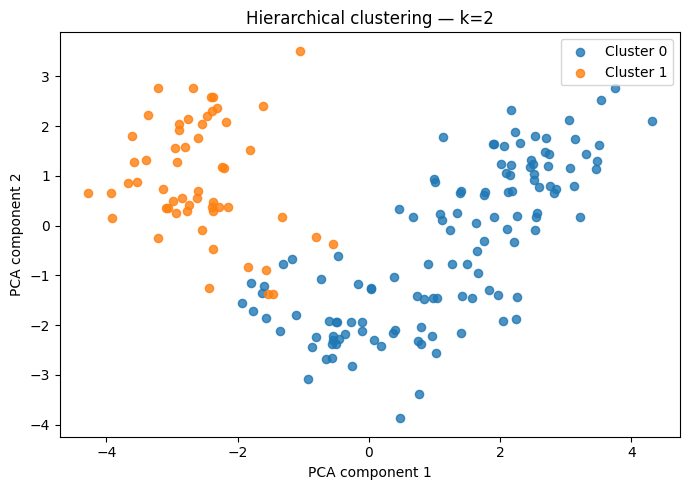

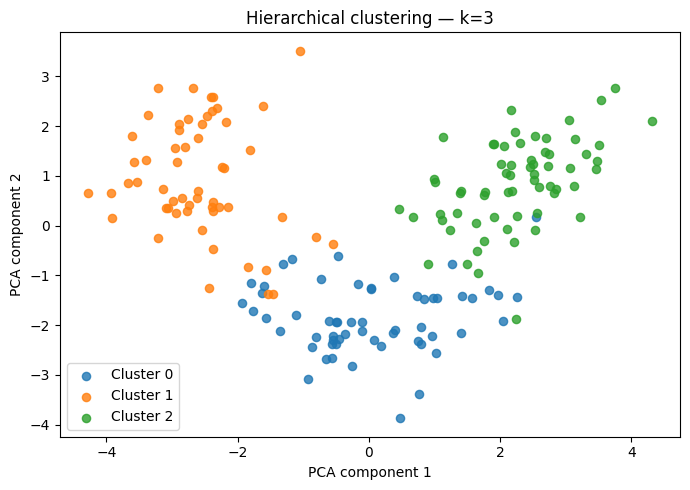

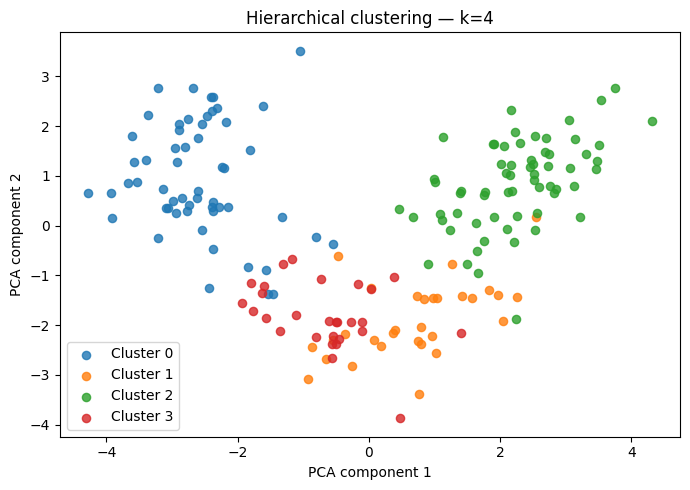

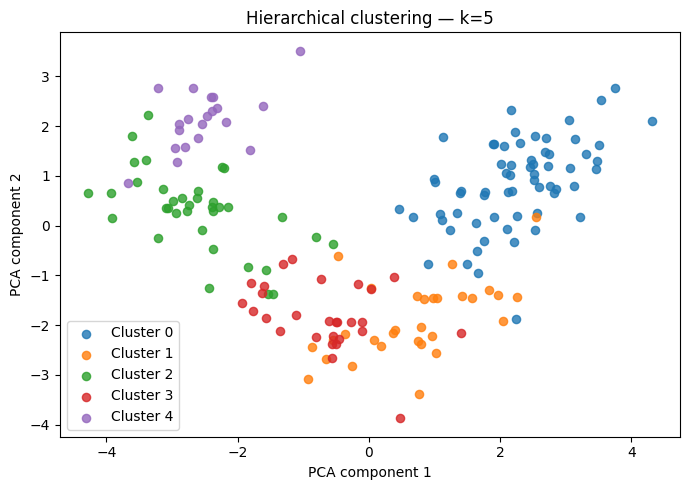

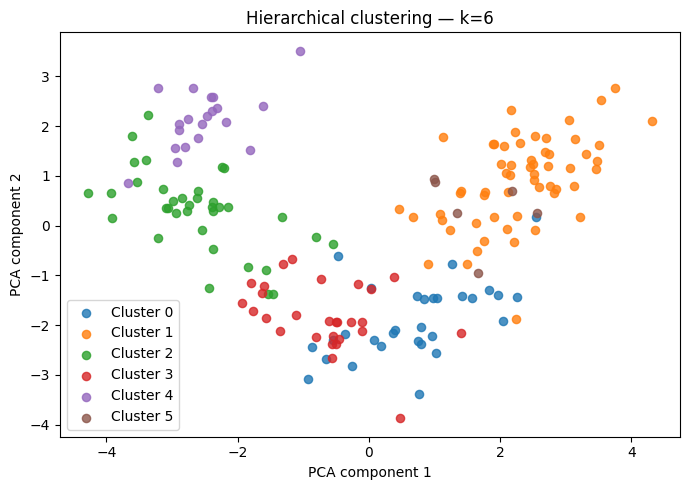

,algorithm,parameter,clusters_excl_noise,noise_points,silhouette,homogeneity,completeness
0,Hierarchical,k=2,2,0,0.267,0.444,0.774
1,Hierarchical,k=3,3,0,0.277,0.790,0.783
2,Hierarchical,k=4,4,0,0.226,0.790,0.649
3,Hierarchical,k=5,5,0,0.187,0.811,0.576
4,Hierarchical,k=6,6,0,0.180,0.835,0.553


In [4]:
hier_results = []
for k in [2, 3, 4, 5, 6]:
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    hier_results.append({"algorithm": "Hierarchical", "parameter": f"k={k}", **evaluate(labels)})
    plot_clusters(labels, f"Hierarchical clustering — k={k}")
hier_table = pd.DataFrame(hier_results)
display(hier_table.round(3))

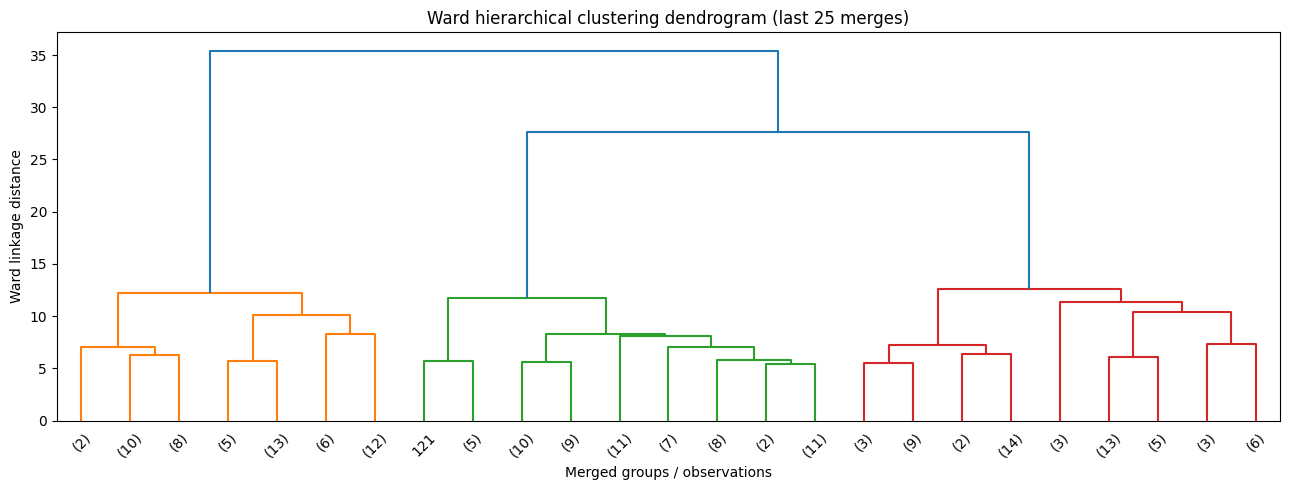

In [5]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=25, show_leaf_counts=True)
plt.title("Ward hierarchical clustering dendrogram (last 25 merges)")
plt.xlabel("Merged groups / observations")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

**Dendrogram interpretation:** Taller vertical joins indicate that more dissimilar groups are being merged. A horizontal cut just below a large jump in linkage height suggests a reasonable number of clusters; it is not a guarantee that clusters match the three wine labels.

## 3. DBSCAN clustering
DBSCAN groups dense regions and labels sparse points as noise (-1). Because the data have 13 standardized dimensions, distances may be less separable than in a two-dimensional dataset. We vary both neighborhood radius (`eps`) and core-point threshold (`min_samples`).

In [6]:
db_results = []
for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5]:
    for min_samples in [3, 5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        db_results.append({"algorithm": "DBSCAN", "parameter": f"eps={eps}, min_samples={min_samples}",
                           "eps": eps, "min_samples": min_samples, **evaluate(labels)})
db_table = pd.DataFrame(db_results)
display(db_table.round(3))

,algorithm,parameter,eps,min_samples,clusters_excl_noise,noise_points,silhouette,homogeneity,completeness
0,DBSCAN,"eps=1.5, min_samples=3",1.5,3,8,147,-0.277,0.189,0.251
1,DBSCAN,"eps=1.5, min_samples=5",1.5,5,0,178,NaN,0.000,1.000
2,DBSCAN,"eps=1.5, min_samples=10",1.5,10,0,178,NaN,0.000,1.000
3,DBSCAN,"eps=2.0, min_samples=3",2.0,3,5,64,0.031,0.442,0.372
4,DBSCAN,"eps=2.0, min_samples=5",2.0,5,5,85,-0.033,0.362,0.325
5,DBSCAN,"eps=2.0, min_samples=10",2.0,10,1,139,0.115,0.289,0.596
6,DBSCAN,"eps=2.5, min_samples=3",2.5,3,1,23,0.135,0.067,0.189
7,DBSCAN,"eps=2.5, min_samples=5",2.5,5,1,24,0.135,0.058,0.158
8,DBSCAN,"eps=2.5, min_samples=10",2.5,10,2,32,0.204,0.504,0.560
9,DBSCAN,"eps=3.0, min_samples=3",3.0,3,2,7,0.191,0.031,0.135


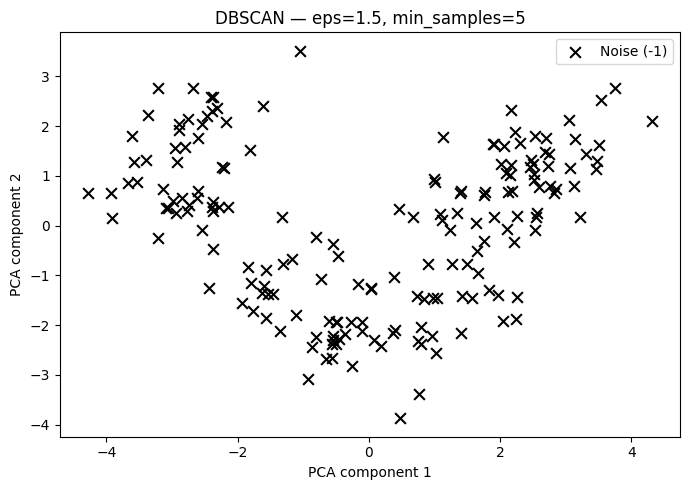

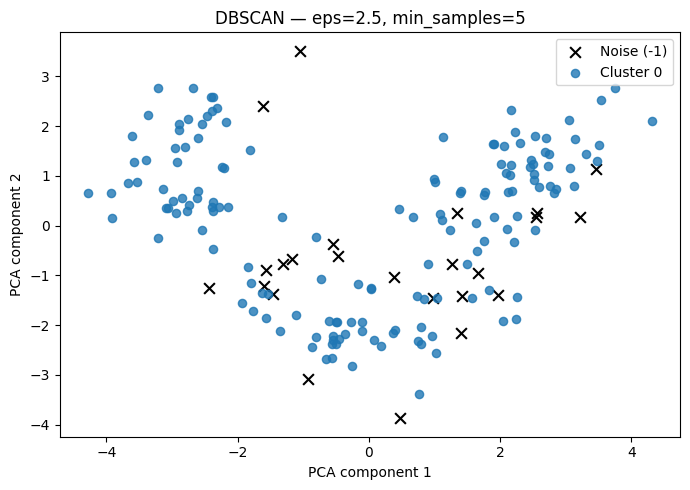

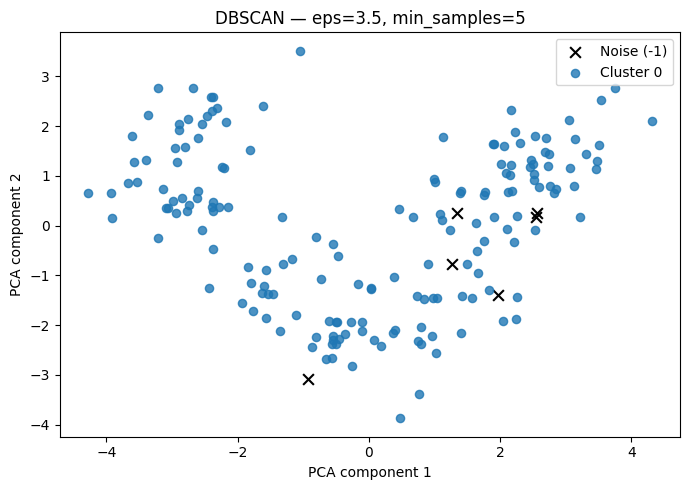

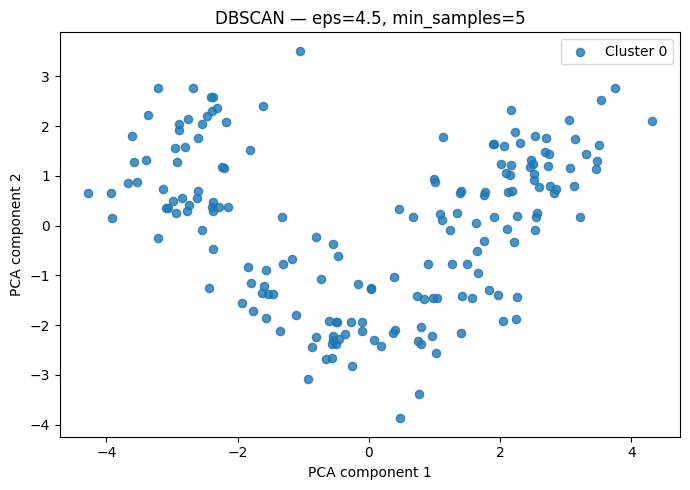

In [7]:
for eps, min_samples in [(1.5, 5), (2.5, 5), (3.5, 5), (4.5, 5)]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    plot_clusters(labels, f"DBSCAN — eps={eps}, min_samples={min_samples}")

**Metric interpretation:** Silhouette measures compactness/separation (higher is better). Homogeneity measures whether each discovered cluster contains one known class; completeness measures whether each known class is grouped together. When all points form one cluster or all are noise, silhouette is undefined and reported as `NaN`. A high homogeneity score alone can be misleading when most observations are classified as noise.

## 4. Comparison and insights

In [8]:
comparison = pd.concat([hier_table, db_table.drop(columns=["eps", "min_samples"])], ignore_index=True)
print("Top settings by silhouette (including noise as a separate label):")
display(comparison.sort_values("silhouette", ascending=False, na_position="last").head(10).round(3))
print("Hierarchical k=3:")
display(hier_table[hier_table.parameter == "k=3"].round(3))
print("DBSCAN configurations with at least 2 non-noise clusters:")
display(db_table[db_table.clusters_excl_noise >= 2].round(3))

Top settings by silhouette (including noise as a separate label):


,algorithm,parameter,clusters_excl_noise,noise_points,silhouette,homogeneity,completeness
1,Hierarchical,k=3,3,0,0.277,0.790,0.783
0,Hierarchical,k=2,2,0,0.267,0.444,0.774
18,DBSCAN,"eps=3.5, min_samples=5",1,6,0.250,0.029,0.216
19,DBSCAN,"eps=3.5, min_samples=10",1,8,0.246,0.025,0.151
2,Hierarchical,k=4,4,0,0.226,0.790,0.649
22,DBSCAN,"eps=4.0, min_samples=10",1,3,0.222,0.014,0.184
20,DBSCAN,"eps=4.0, min_samples=3",2,0,0.222,0.014,0.184
21,DBSCAN,"eps=4.0, min_samples=5",1,3,0.222,0.014,0.184
15,DBSCAN,"eps=3.0, min_samples=5",1,11,0.218,0.031,0.145
17,DBSCAN,"eps=3.5, min_samples=3",2,3,0.216,0.029,0.187


Hierarchical k=3:


,algorithm,parameter,clusters_excl_noise,noise_points,silhouette,homogeneity,completeness
1,Hierarchical,k=3,3,0,0.277,0.79,0.783


DBSCAN configurations with at least 2 non-noise clusters:


,algorithm,parameter,eps,min_samples,clusters_excl_noise,noise_points,silhouette,homogeneity,completeness
0,DBSCAN,"eps=1.5, min_samples=3",1.5,3,8,147,-0.277,0.189,0.251
3,DBSCAN,"eps=2.0, min_samples=3",2.0,3,5,64,0.031,0.442,0.372
4,DBSCAN,"eps=2.0, min_samples=5",2.0,5,5,85,-0.033,0.362,0.325
8,DBSCAN,"eps=2.5, min_samples=10",2.5,10,2,32,0.204,0.504,0.560
9,DBSCAN,"eps=3.0, min_samples=3",3.0,3,2,7,0.191,0.031,0.135
12,DBSCAN,"eps=3.5, min_samples=3",3.5,3,2,3,0.216,0.029,0.187
15,DBSCAN,"eps=4.0, min_samples=3",4.0,3,2,0,0.222,0.014,0.184


### Discussion
- **Standardization:** Essential because chemical features have different scales; otherwise high-magnitude features would dominate Euclidean distances.
- **Hierarchical:** Setting `n_clusters` controls the granularity directly. A smaller k combines distinct groups, while a larger k fragments them. Ward clustering assigns every sample to a group and exposes nested relationships in a dendrogram. Its disadvantages include sensitivity to outliers and the absence of an explicit noise class.
- **DBSCAN:** Increasing `eps` generally connects more points and reduces noise; increasing `min_samples` makes the density requirement stricter and can increase noise. Small `eps` may label most observations as noise; large `eps` may merge nearly everything into one cluster. DBSCAN does not require choosing k, but its performance can suffer in high-dimensional data with uneven density.
- **Comparison:** Examine the displayed metric table rather than assuming either algorithm wins universally. Compare silhouette only where defined, and read it alongside the noise count, homogeneity and completeness. Since the wine dataset has three known classes, hierarchical k=3 is a useful reference, not a guaranteed optimum.
- **Decision:** For this standardized, modest-size, 13-dimensional dataset, Ward hierarchical clustering is a useful baseline. DBSCAN is especially valuable for discovering noise, but choosing density parameters is challenging.

**Limitations:** PCA plots can conceal separation in the original 13-dimensional space. Homogeneity and completeness use known class labels only after clustering. Treat all evaluation scores as descriptive, not as supervised prediction accuracy.

## Reproducibility
Run all cells from top to bottom with Python 3 and `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `scipy` installed.